In [1]:
import pandas as pd

df = pd.read_csv("data.csv")

print("Shape:", df.shape)
df.head()

Shape: (336, 1)


,\tX1\tX2\tX3\tX4\tX5\tX6\tX7\tX8\tX9\tX10\tX11\tX12\tX13\tX14\tX15\tX16\tX17\tX18\tX19\tX20\tX21\tX22\tX23\tY
0,ID\tLIMIT_BAL\tSEX\tEDUCATION\tMARRIAGE\tAGE\t...
1,1\t20000\t2\t2\t1\t24\t2\t2\t-1\t-1\t-2\t-2\t3...
2,2\t120000\t2\t2\t2\t26\t-1\t2\t0\t0\t0\t2\t268...
3,3\t90000\t2\t2\t2\t34\t0\t0\t0\t0\t0\t0\t29239...
4,4\t50000\t2\t2\t1\t37\t0\t0\t0\t0\t0\t0\t46990...


In [7]:
import pandas as pd
import xlrd

df = pd.read_excel("default of credit card clients.xls", header=1)
print(df.columns.tolist())

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [6]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
df.head()


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [21]:
df = df.rename(columns={"default payment next month": "default"})
#df = df.drop(columns=["ID"])
df.columns.tolist()

['LIMIT_BAL',
 'SEX',
 'EDUCATION',
 'MARRIAGE',
 'AGE',
 'PAY_0',
 'PAY_2',
 'PAY_3',
 'PAY_4',
 'PAY_5',
 'PAY_6',
 'BILL_AMT1',
 'BILL_AMT2',
 'BILL_AMT3',
 'BILL_AMT4',
 'BILL_AMT5',
 'BILL_AMT6',
 'PAY_AMT1',
 'PAY_AMT2',
 'PAY_AMT3',
 'PAY_AMT4',
 'PAY_AMT5',
 'PAY_AMT6',
 'default']

In [12]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0
PAY_5,30000.0,-0.266200,1.133187,-2.0,-1.00,0.0,0.00,8.0


In [13]:
for col in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(df[col].value_counts().sort_index())
    print()

SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64



In [14]:
df["PAY_0"].value_counts().sort_index()

PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64

In [15]:
df.duplicated().sum()

np.int64(35)

In [16]:
df["EDUCATION"] = df["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
df["MARRIAGE"] = df["MARRIAGE"].replace({0: 3})

print(df["EDUCATION"].value_counts().sort_index())
print(df["MARRIAGE"].value_counts().sort_index())

EDUCATION
1    10585
2    14030
3     4917
4      468
Name: count, dtype: int64
MARRIAGE
1    13659
2    15964
3      377
Name: count, dtype: int64


In [17]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after:", df.shape)

Duplicates before: 35
Shape after: (29965, 24)


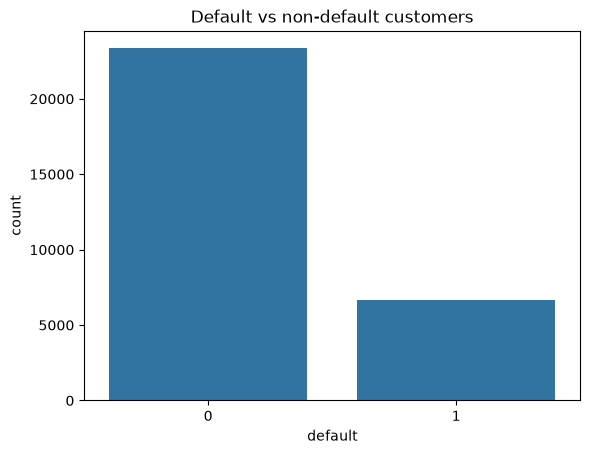

default
0    0.778742
1    0.221258
Name: proportion, dtype: float64


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x="default", data=df)
plt.title("Default vs non-default customers")
plt.show()

print(df["default"].value_counts(normalize=True))

In [23]:
df.head()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


PAY_0
-2    0.132364
-1    0.167899
 0    0.128113
 1    0.340333
 2    0.691298
 3    0.757764
 4    0.684211
 5    0.500000
 6    0.545455
 7    0.777778
 8    0.578947
Name: default, dtype: float64


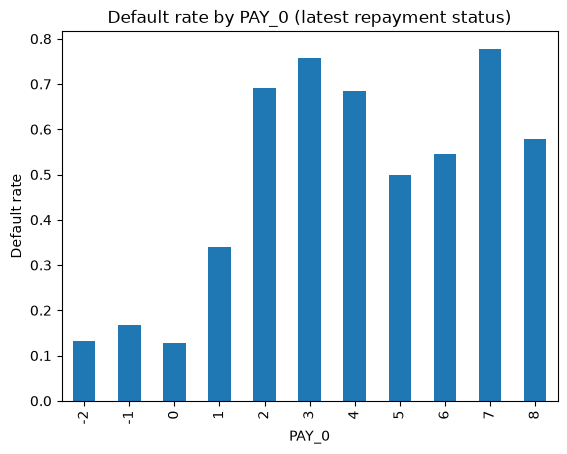

In [24]:
rate = df.groupby("PAY_0")["default"].mean()
print(rate)

rate.plot(kind="bar")
plt.ylabel("Default rate")
plt.title("Default rate by PAY_0 (latest repayment status)")
plt.show()

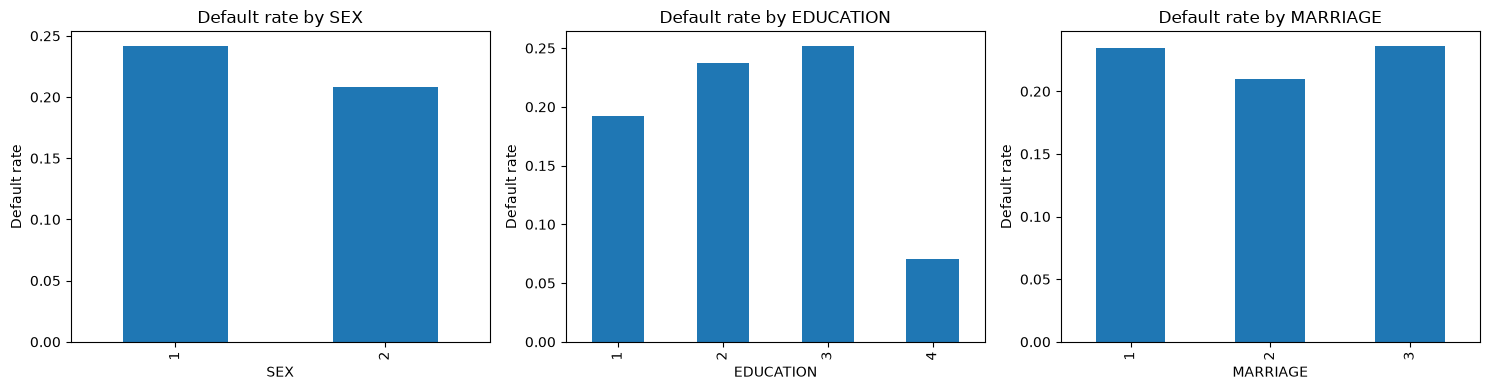

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, ["SEX", "EDUCATION", "MARRIAGE"]):
    df.groupby(col)["default"].mean().plot(kind="bar", ax=ax)
    ax.set_title(f"Default rate by {col}")
    ax.set_ylabel("Default rate")

plt.tight_layout()
plt.show()

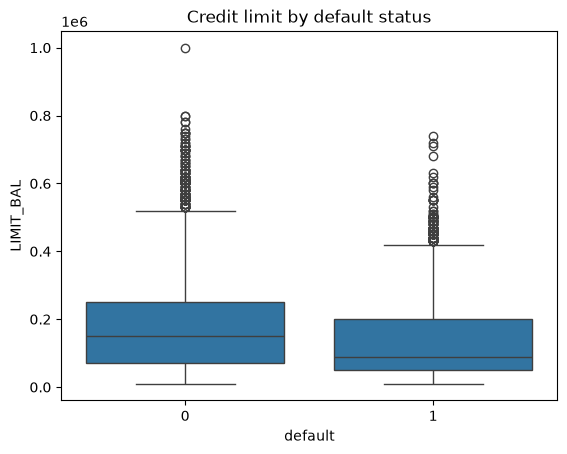

In [26]:
sns.boxplot(x="default", y="LIMIT_BAL", data=df)
plt.title("Credit limit by default status")
plt.show()

default      1.000000
PAY_0        0.324964
PAY_2        0.263656
PAY_3        0.235230
PAY_4        0.216551
PAY_5        0.204059
PAY_6        0.186740
EDUCATION    0.033862
AGE          0.013619
BILL_AMT6   -0.005469
BILL_AMT5   -0.006859
BILL_AMT4   -0.010259
BILL_AMT3   -0.014182
BILL_AMT2   -0.014302
BILL_AMT1   -0.019758
MARRIAGE    -0.027259
SEX         -0.039742
PAY_AMT6    -0.053250
PAY_AMT5    -0.055194
PAY_AMT3    -0.056319
PAY_AMT4    -0.056898
PAY_AMT2    -0.058643
PAY_AMT1    -0.073015
LIMIT_BAL   -0.153871
Name: default, dtype: float64


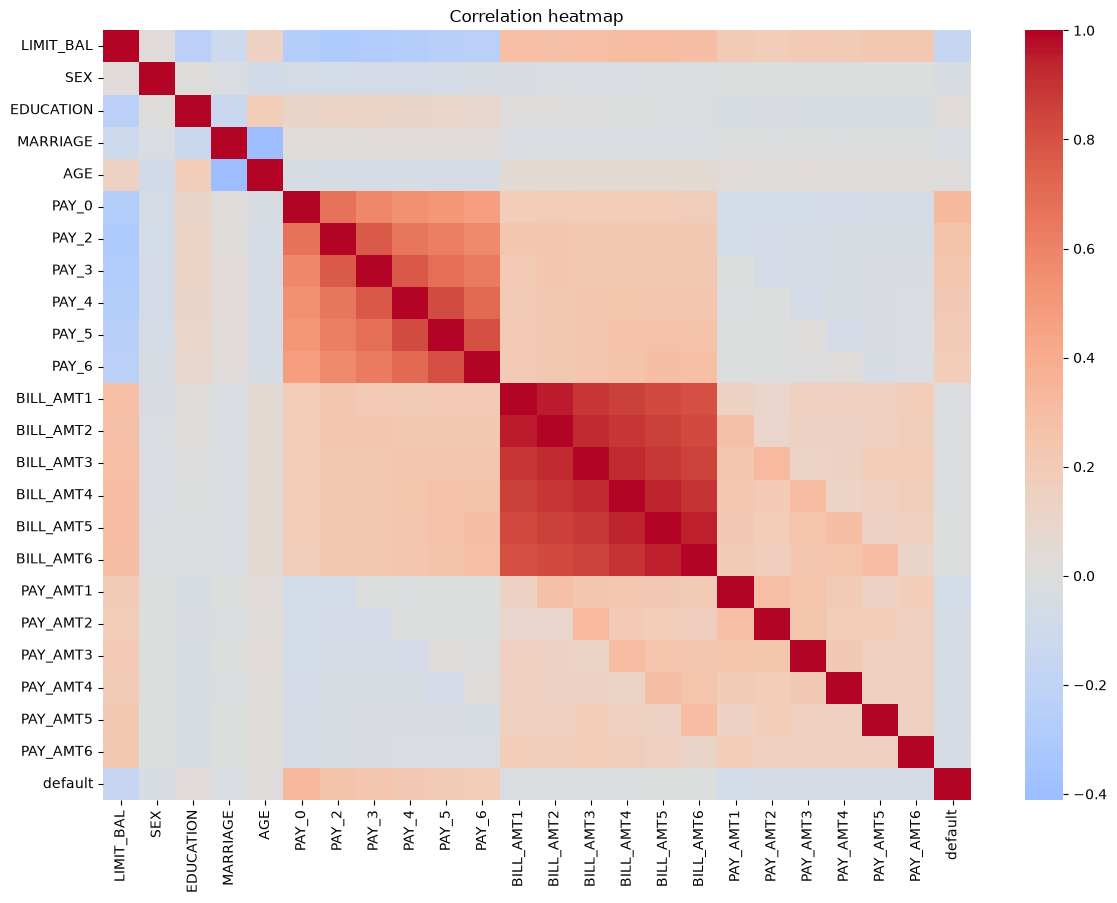

In [27]:
corr = df.corr()
print(corr["default"].sort_values(ascending=False))

plt.figure(figsize=(14, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

In [28]:
pay_cols  = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
amt_cols  = [f"PAY_AMT{i}" for i in range(1, 7)]

df["avg_delay"]   = df[pay_cols].mean(axis=1)
df["max_delay"]   = df[pay_cols].max(axis=1)
df["months_late"] = (df[pay_cols] > 0).sum(axis=1)
df["avg_bill"]    = df[bill_cols].mean(axis=1)
df["total_paid"]  = df[amt_cols].sum(axis=1)
df["utilization"] = df["avg_bill"] / df["LIMIT_BAL"]
df["pay_ratio"]   = df["total_paid"] / df[bill_cols].sum(axis=1).clip(lower=1)
df["pay_ratio"]   = df["pay_ratio"].clip(upper=5)

df[["avg_delay", "max_delay", "months_late", "utilization", "pay_ratio"]].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_delay,29965.0,-0.180978,0.981368,-2.00000,-0.833333,0.000000,0.000000,6.000000
max_delay,29965.0,0.439146,1.344934,-2.00000,0.000000,0.000000,2.000000,8.000000
months_late,29965.0,0.834273,1.554821,0.00000,0.000000,0.000000,1.000000,6.000000
utilization,29965.0,0.373480,0.351867,-0.23259,0.030300,0.285629,0.688454,5.364308
pay_ratio,29965.0,0.404224,0.700384,0.00000,0.041340,0.088221,0.614180,5.000000


In [29]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

X = df.drop(columns=["default"])
y = df["default"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

(23972, 30) (5993, 30)
0.22125813449023862 0.22125813449023862


In [30]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score)

def make_pipe(model):
    return Pipeline([("prep", clone(preprocess)), ("model", model)])

def evaluate(name, pipe):
    pred  = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    }

lr = make_pipe(LogisticRegression(max_iter=1000))
lr.fit(X_train, y_train)
evaluate("Logistic Regression", lr)

{'Model': 'Logistic Regression',
 'Precision': 0.6485148514851485,
 'Recall': 0.29638009049773756,
 'F1': 0.40683229813664595,
 'ROC-AUC': 0.7528865908414428}

In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

dt = make_pipe(DecisionTreeClassifier(max_depth=5, random_state=42))
rf = make_pipe(RandomForestClassifier(
        n_estimators=200, max_depth=10, random_state=42, n_jobs=-1))

dt.fit(X_train, y_train)
rf.fit(X_train, y_train)

evaluate("Decision Tree", dt), evaluate("Random Forest", rf)

({'Model': 'Decision Tree',
  'Precision': 0.6324257425742574,
  'Recall': 0.385369532428356,
  'F1': 0.47891283973758203,
  'ROC-AUC': 0.7568750745341073},
 {'Model': 'Random Forest',
  'Precision': 0.6630286493860846,
  'Recall': 0.3665158371040724,
  'F1': 0.4720738222438077,
  'ROC-AUC': 0.7746173431050981})

                     Precision  Recall     F1  ROC-AUC
Model                                                 
Logistic Regression      0.649   0.296  0.407    0.753
Decision Tree            0.632   0.385  0.479    0.757
Random Forest            0.663   0.367  0.472    0.775


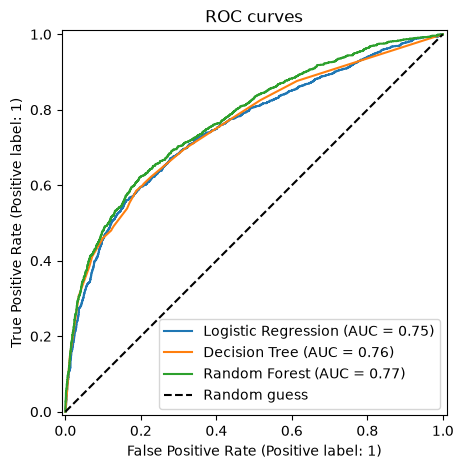

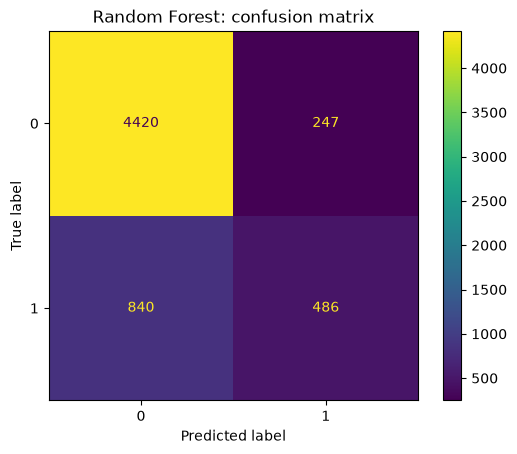

In [32]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

models = {"Logistic Regression": lr, "Decision Tree": dt, "Random Forest": rf}

results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model")
print(results.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
for name, m in models.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.legend()
plt.title("ROC curves")
plt.show()

ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test)
plt.title("Random Forest: confusion matrix")
plt.show()

In [33]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

lr_bal = make_pipe(LogisticRegression(max_iter=1000, class_weight="balanced"))
rf_bal = make_pipe(RandomForestClassifier(
        n_estimators=200, max_depth=10, class_weight="balanced",
        random_state=42, n_jobs=-1))
lr_bal.fit(X_train, y_train)
rf_bal.fit(X_train, y_train)

models["LogReg (balanced)"] = lr_bal
models["RandomForest (balanced)"] = rf_bal
results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model")
print(results.round(3))

                         Precision  Recall     F1  ROC-AUC
Model                                                     
Logistic Regression          0.649   0.296  0.407    0.753
Decision Tree                0.632   0.385  0.479    0.757
Random Forest                0.663   0.367  0.472    0.775
LogReg (balanced)            0.443   0.605  0.511    0.755
RandomForest (balanced)      0.485   0.590  0.532    0.774


In [34]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(rf_bal, X_train, y_train, cv=cv, scoring="roc_auc")
print(scores.round(3), "mean:", scores.mean().round(3))

[0.789 0.787 0.78  0.771 0.799] mean: 0.785


In [35]:
proba = rf_bal.predict_proba(X_test)[:, 1]
for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (proba >= t).astype(int)
    print(t, round(precision_score(y_test, pred), 3),
             round(recall_score(y_test, pred), 3),
             round(f1_score(y_test, pred), 3))

0.3 0.314 0.851 0.459
0.4 0.393 0.71 0.506
0.5 0.485 0.59 0.532
0.6 0.552 0.498 0.524


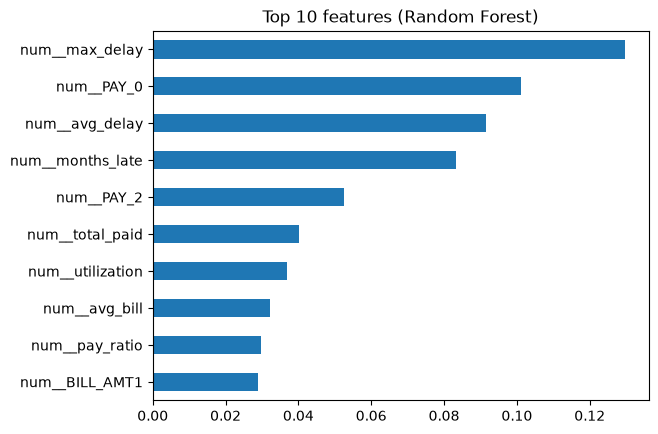

array([[0.67917545, 0.32082455]])

In [36]:
import joblib

names = rf_bal.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_bal.named_steps["model"].feature_importances_, index=names)
ax = imp.sort_values(ascending=False).head(10).plot(kind="barh")
ax.invert_yaxis()
plt.title("Top 10 features (Random Forest)")
plt.show()

joblib.dump(rf_bal, "credit_model.joblib")

loaded = joblib.load("credit_model.joblib")
loaded.predict_proba(X_test.iloc[[0]])

In [40]:
import os
os.makedirs("images", exist_ok=True)

In [41]:
plt.savefig("images/roc_curves.png", dpi=150, bbox_inches="tight")
plt.savefig("images/confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>